In [23]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
plt.style.use('seaborn-v0_8-whitegrid')

In [24]:
file_names = ["time_domain_signal1.csv","time_domain_signal2.csv","time_domain_signal3.csv","time_domain_signal4.csv","time_domain_signal5.csv",]
signals = []
for name in file_names:
    data = np.loadtxt(name, delimiter=",")
    signals.append(data)
    print(name, "-> number of samples =", len(data))

time_domain_signal1.csv -> number of samples = 501
time_domain_signal2.csv -> number of samples = 501
time_domain_signal3.csv -> number of samples = 501
time_domain_signal4.csv -> number of samples = 1002
time_domain_signal5.csv -> number of samples = 1002


In [25]:
fs = 501
print("sampling rate used:", fs, "Hz")

sampling rate used: 501 Hz


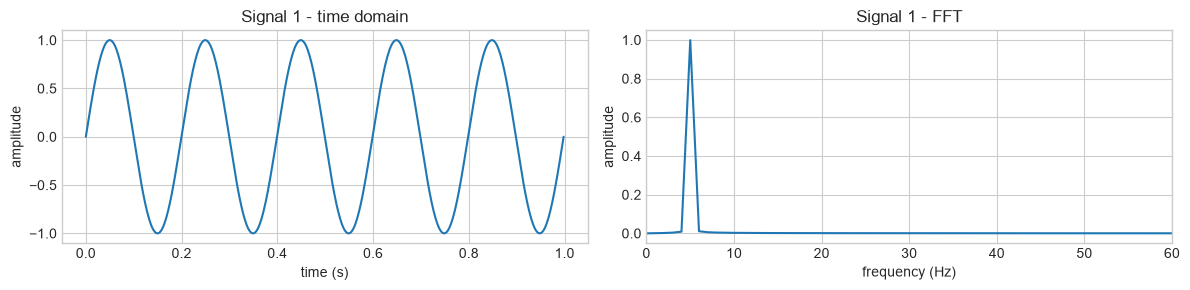

Signal 1: strongest frequency = 5.00 Hz


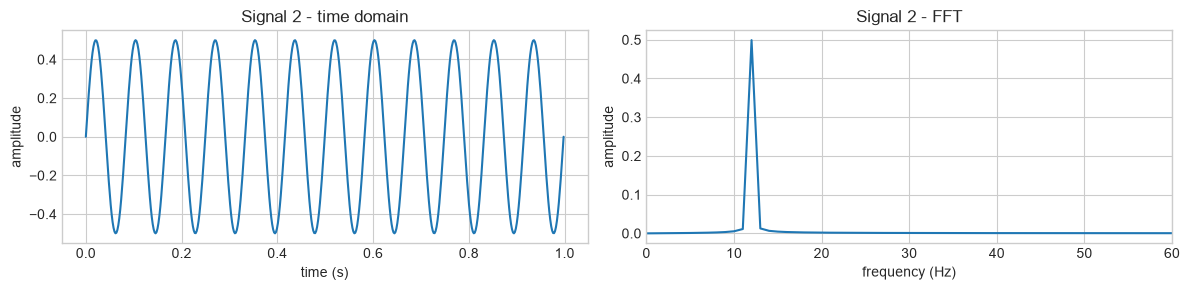

Signal 2: strongest frequency = 12.00 Hz


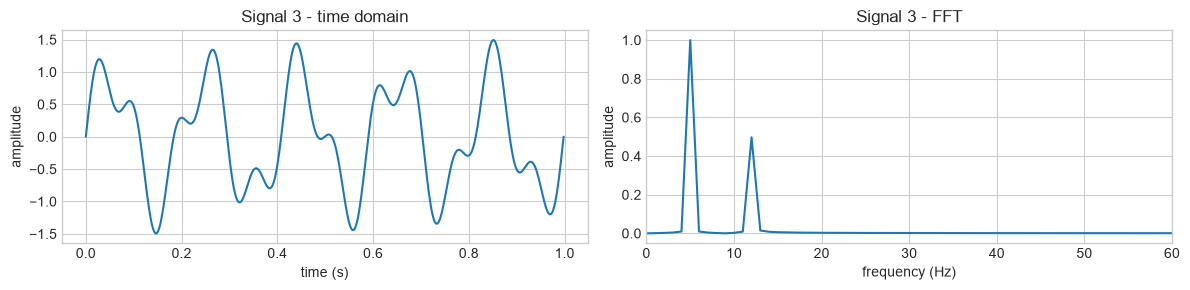

Signal 3: strongest frequency = 5.00 Hz


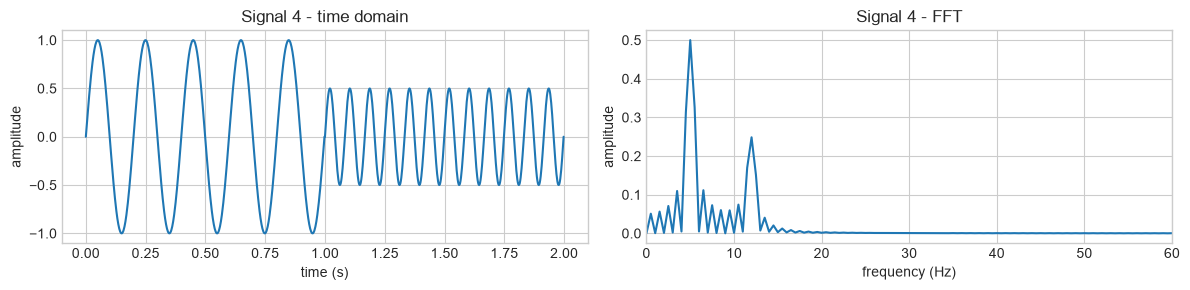

Signal 4: strongest frequency = 5.00 Hz


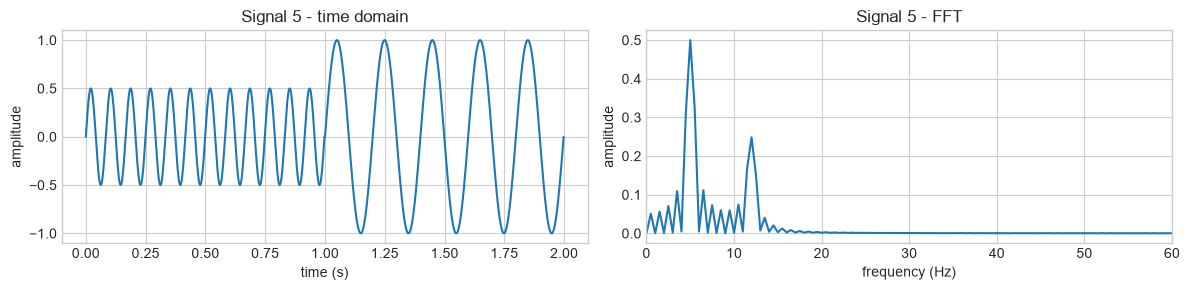

Signal 5: strongest frequency = 5.00 Hz


In [26]:
# FFT part
for i in range(5):
    x = signals[i]
    n = len(x)
    t = np.arange(n) / fs
    
    # doing the FFT
    X = np.fft.rfft(x)
    freq = np.fft.rfftfreq(n, d=1/fs)
    mag = np.abs(X) / n * 2   # scaling so the height matches the real amplitude

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3))
    ax1.plot(t, x)
    ax1.set_title(f"Signal {i+1} - time domain")
    ax1.set_xlabel("time (s)")
    ax1.set_ylabel("amplitude")
    ax2.plot(freq, mag)
    ax2.set_xlim(0, 60)  
    ax2.set_title(f"Signal {i+1} - FFT")
    ax2.set_xlabel("frequency (Hz)")
    ax2.set_ylabel("amplitude")
    plt.tight_layout()
    plt.show()

    peak_index = np.argmax(mag[1:]) + 1   
    print(f"Signal {i+1}: strongest frequency = {freq[peak_index]:.2f} Hz")

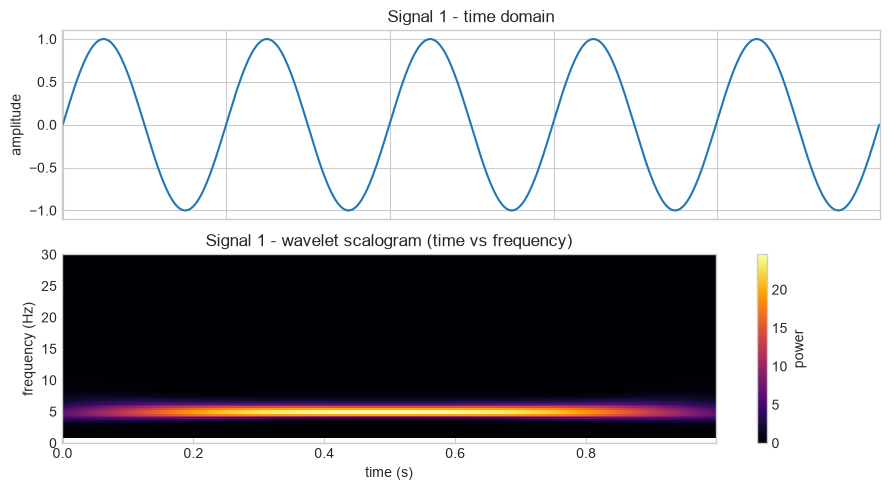

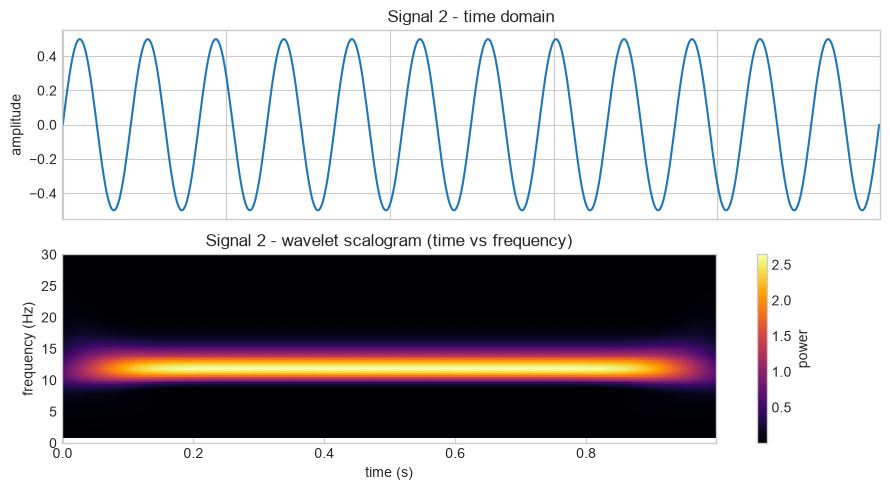

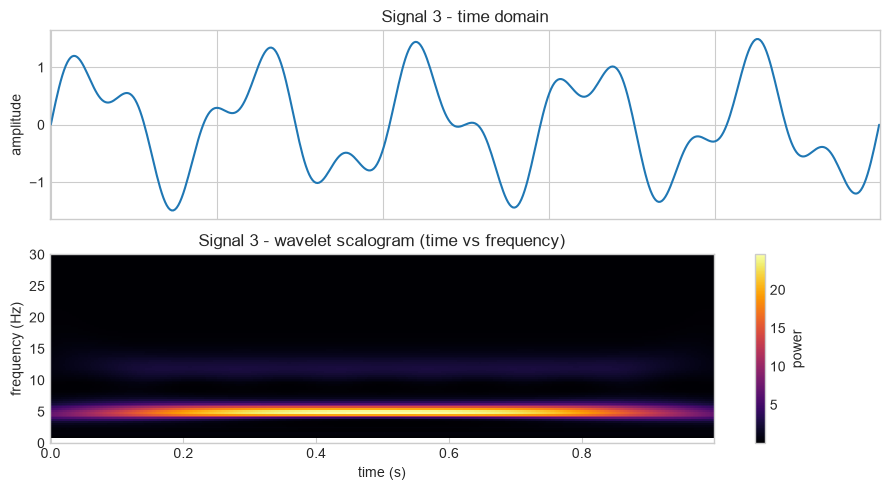

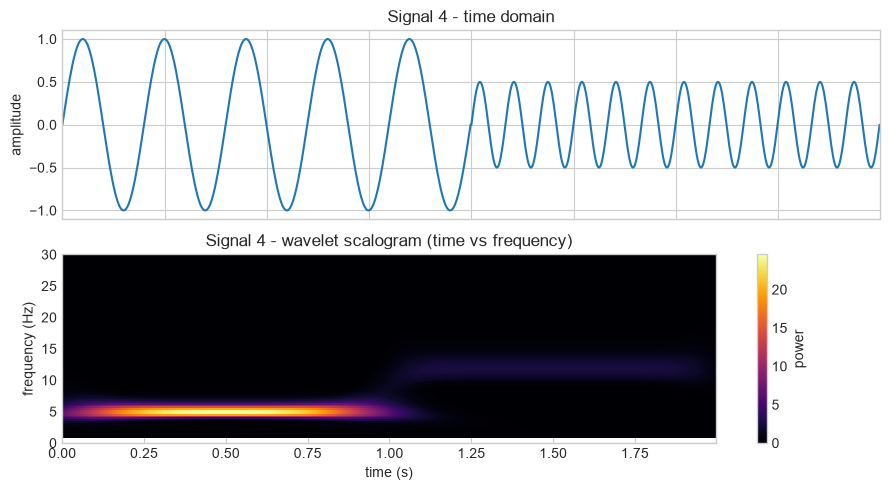

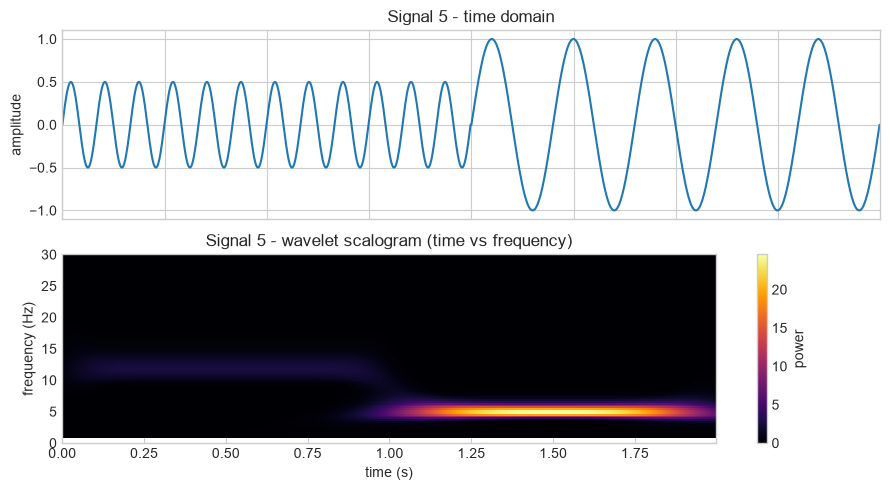

In [ ]:

# Wavelet part 
for i in range(5):
    x = signals[i]
    n = len(x)
    t = np.arange(n) / fs
    wanted_freqs = np.linspace(30, 1, 100)
    scales = pywt.frequency2scale('cmor1.5-1.0', wanted_freqs / fs)
    coeffs, freqs = pywt.cwt(x, scales, 'cmor1.5-1.0', sampling_period=1/fs)
    power = np.abs(coeffs) ** 2
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    ax1.plot(t, x)
    ax1.set_title(f"Signal {i+1} - time domain")
    ax1.set_ylabel("amplitude")
    im = ax2.pcolormesh(t, freqs, power, shading='auto', cmap='inferno')
    ax2.set_ylim(0, 30)   
    ax2.set_title(f"Signal {i+1} - wavelet scalogram (time vs frequency)")
    ax2.set_xlabel("time (s)")
    ax2.set_ylabel("frequency (Hz)")
    fig.colorbar(im, ax=ax2, label="power")

    plt.tight_layout()
    plt.show()

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt

In [29]:
try:
    noisy_signal = pd.read_csv('noisy_signal_1.csv', header=None).values.flatten()
    transient = pd.read_csv('transient1.csv', header=None).values.flatten()
except FileNotFoundError:
    pass

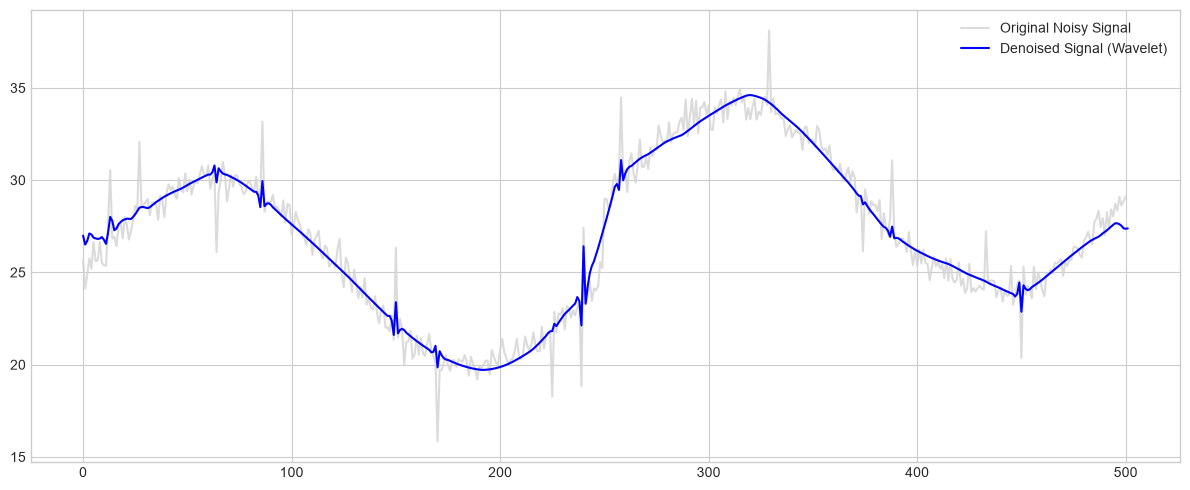

In [30]:
def denoise_signal(data, wavelet='db4', level=1):
    coeffs = pywt.wavedec(data, wavelet, mode='per')
    sigma = (1/0.6745) * np.median(np.abs(coeffs[-1] - np.median(coeffs[-1])))
    uthresh = sigma * np.sqrt(2 * np.log(len(data)))
    coeffs_thresh = [coeffs[0]] + [pywt.threshold(c, value=uthresh, mode='soft') for c in coeffs[1:]]
    return pywt.waverec(coeffs_thresh, wavelet, mode='per')
denoised_signal = denoise_signal(noisy_signal, wavelet='sym4', level=2)
plt.figure(figsize=(12, 5))
plt.plot(noisy_signal, label='Original Noisy Signal', color='lightgray', alpha=0.8)
plt.plot(denoised_signal, label='Denoised Signal (Wavelet)', color='blue', linewidth=1.5)
plt.legend()
plt.tight_layout()
plt.show()

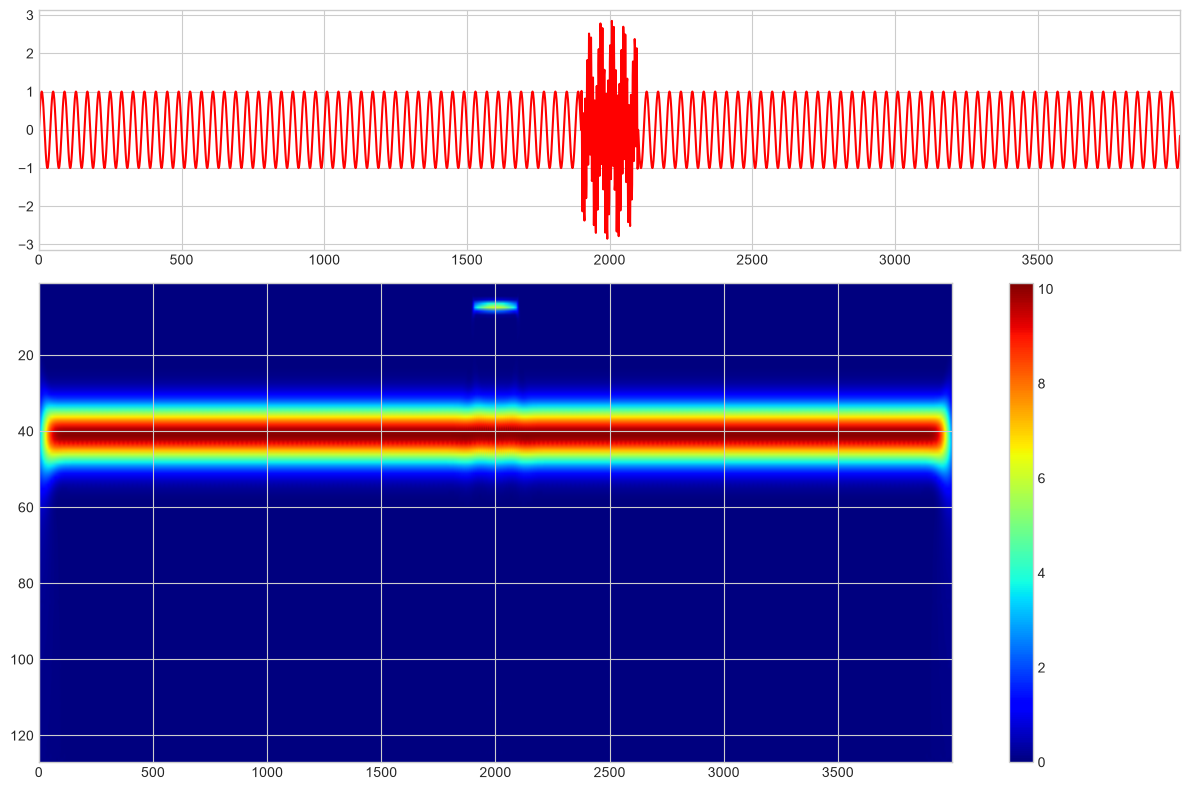

In [31]:
wavelet_type = 'cmor1.5-1.0'
scales = np.arange(1, 128)

coefficients, frequencies = pywt.cwt(transient, scales, wavelet_type)
power = (np.abs(coefficients)) ** 2

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={'height_ratios': [1, 2]})

ax1.plot(transient, color='red')
ax1.set_xlim([0, len(transient)-1])

im = ax2.imshow(power, extent=[0, len(transient)-1, scales[-1], scales[0]], 
                aspect='auto', cmap='jet', interpolation='bilinear')
fig.colorbar(im, ax=ax2)

plt.tight_layout()
plt.show()

In [35]:
import sys
print(sys.executable)

c:\Python314\python.exe


In [36]:
import sys
!{sys.executable} -m pip install pywavelets

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 10

In [ ]:
chirp_df = pd.read_csv('chirp1.csv', header=None)
chirp_signal = chirp_df.values.flatten().astype(float)

fs = 1.0
dt = 1.0 / fs
n_chirp = len(chirp_signal)
t_chirp = np.arange(n_chirp) * dt
print(chirp_signal.shape)

(4000,)


In [ ]:
wavelet = 'cmor1.5-1.0'
scales = np.arange(1, 128)
coefficients, frequencies = pywt.cwt(chirp_signal, scales, wavelet, sampling_period=dt)
power = np.abs(coefficients) ** 2

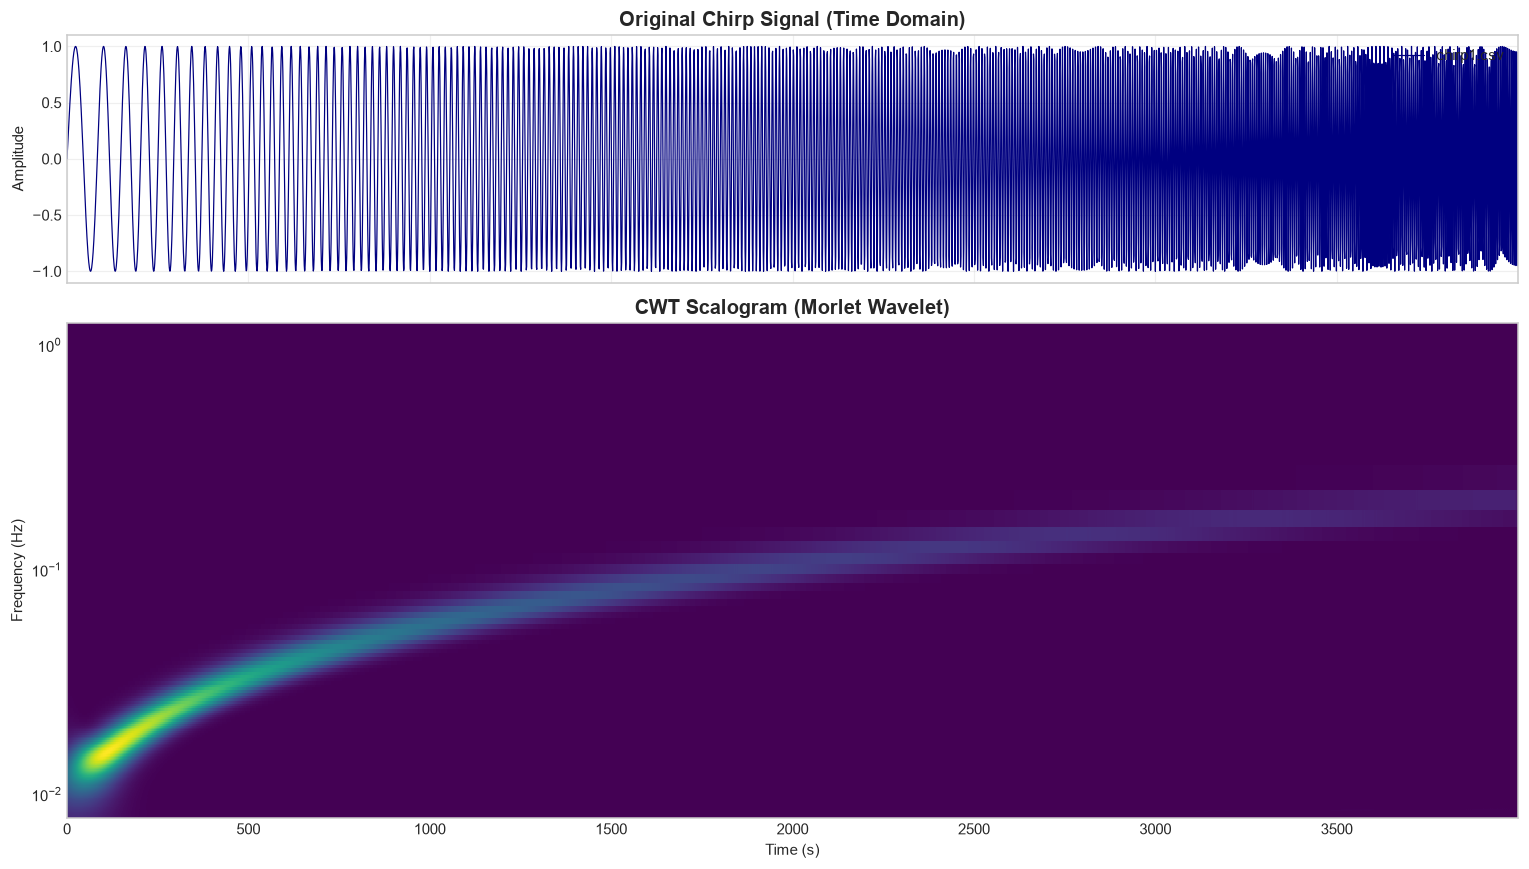

In [42]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [1, 2]})

axes[0].plot(t_chirp, chirp_signal, color='navy', linewidth=0.8)
axes[0].set_title('Original Chirp Signal (Time Domain)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Amplitude')
axes[0].legend(['chirp1.csv'], loc='upper right')
im = axes[1].pcolormesh(t_chirp, frequencies, power, cmap='viridis', shading='auto')
axes[1].set_title('CWT Scalogram (Morlet Wavelet)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_yscale('log')
plt.tight_layout()
plt.savefig('chirp_scalogram.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pywt

transient_df = pd.read_csv('transient1.csv', header=None)
transient_signal = transient_df.values.flatten().astype(float)

fs = 1.0
dt = 1.0 / fs
n_transient = len(transient_signal)
t_transient = np.arange(n_transient) * dt
print(transient_signal.shape)

wavelet = 'cmor1.5-1.0'
scales = np.arange(1, 128)
coefficients, frequencies = pywt.cwt(transient_signal, scales, wavelet, sampling_period=dt)
power = np.abs(coefficients) ** 2

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [1, 2]})

axes[0].plot(t_transient, transient_signal, color='navy', linewidth=0.8)
axes[0].set_title('Original Transient Signal (Time Domain)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Amplitude')
axes[0].legend(['transient1_2.csv'], loc='upper right')

im = axes[1].pcolormesh(t_transient, frequencies, power, cmap='viridis', shading='auto')
axes[1].set_title('CWT Scalogram (Morlet Wavelet)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_yscale('log')

plt.tight_layout()
plt.savefig('transient_scalogram.png', dpi=150, bbox_inches='tight')
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'transient1_2.csv'